In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


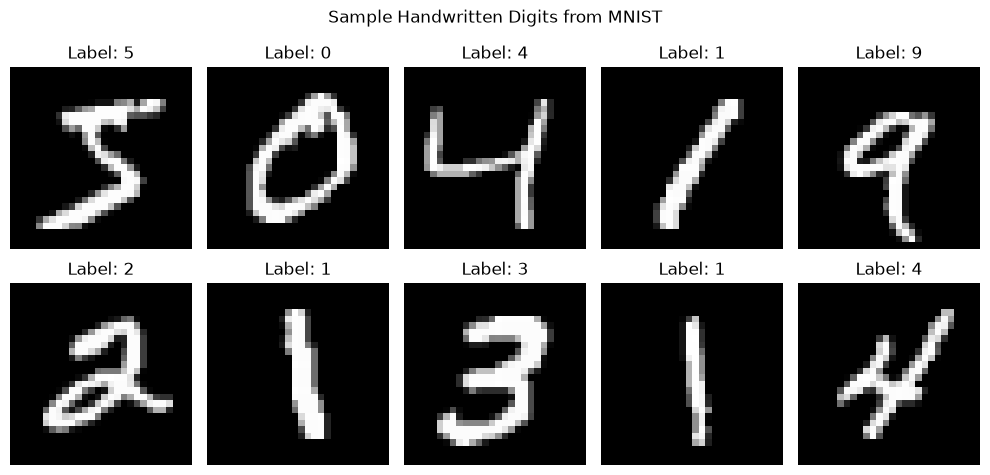

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample Handwritten Digits from MNIST")
plt.tight_layout()
plt.show()

In [4]:
print("Training dataset size:", len(X_train))
print("Testing dataset size:", len(X_test))

print("Image height:", X_train.shape[1])
print("Image width:", X_train.shape[2])

print("Unique digit classes:", np.unique(y_train))

Training dataset size: 60000
Testing dataset size: 10000
Image height: 28
Image width: 28
Unique digit classes: [0 1 2 3 4 5 6 7 8 9]


In [5]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Data preprocessing completed!")

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Data preprocessing completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [6]:
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dropout(0.2),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

C:\Users\Hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9114 - loss: 0.2998 - val_accuracy: 0.9690 - val_loss: 0.1100
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9569 - loss: 0.1423 - val_accuracy: 0.9762 - val_loss: 0.0803
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9659 - loss: 0.1088 - val_accuracy: 0.9772 - val_loss: 0.0805
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - accuracy: 0.9708 - loss: 0.0903 - val_accuracy: 0.9788 - val_loss: 0.0733
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9745 - loss: 0.0796 - val_accuracy: 0.9768 - val_loss: 0.0799
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.9771 - loss: 0.0698 - val_accuracy: 0.9802 - val_loss: 0.0683
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.9788 - loss: 0.0633 - val_accuracy: 0.9788 - val_loss: 0.0759
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9819 - loss: 0

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.0941
Test Accuracy: 97.43 %


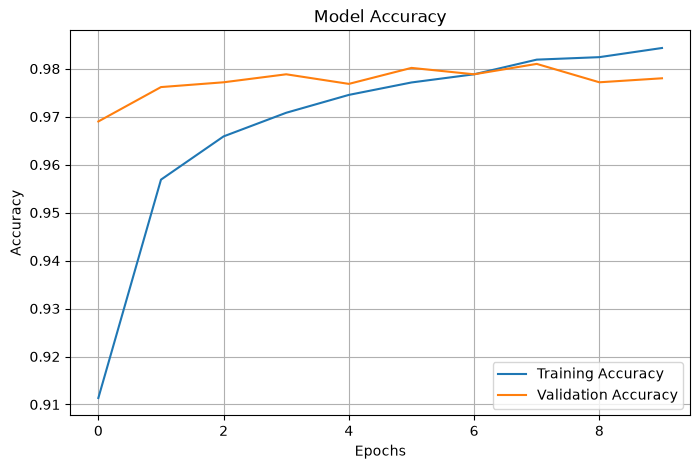

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

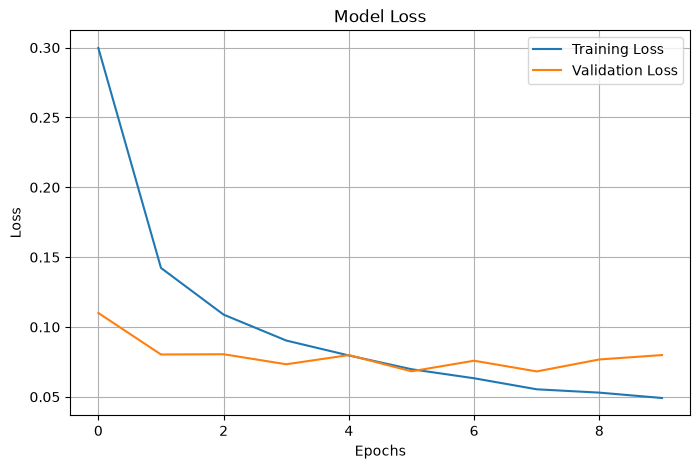

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
y_probability = model.predict(X_test)

y_pred = np.argmax(y_probability, axis=1)

print("Actual digits:", y_test[:10])
print("Predicted digits:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Actual digits: [7 2 1 0 4 1 4 9 5 9]
Predicted digits: [7 2 1 0 4 1 4 9 5 9]


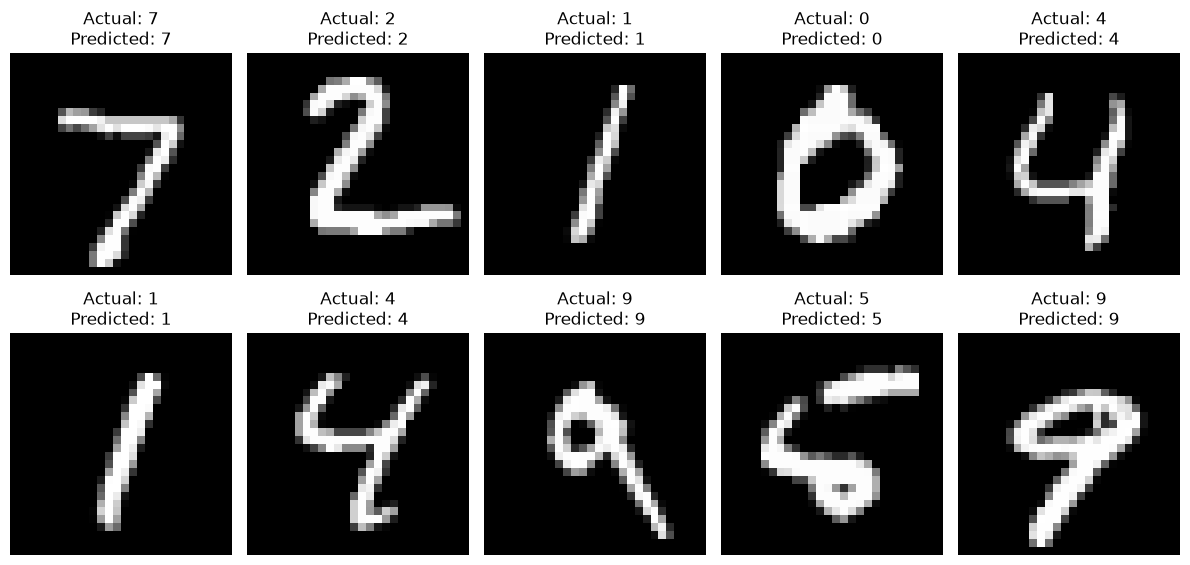

In [13]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i], cmap='gray')

    predicted = y_pred[i]
    actual = y_test[i]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9838    0.9929    0.9883       980
           1     0.9826    0.9938    0.9882      1135
           2     0.9825    0.9787    0.9806      1032
           3     0.9310    0.9881    0.9587      1010
           4     0.9795    0.9745    0.9770       982
           5     0.9665    0.9709    0.9687       892
           6     0.9821    0.9739    0.9780       958
           7     0.9830    0.9543    0.9684      1028
           8     0.9850    0.9446    0.9644       974
           9     0.9692    0.9683    0.9688      1009

    accuracy                         0.9743     10000
   macro avg     0.9745    0.9740    0.9741     10000
weighted avg     0.9746    0.9743    0.9743     10000



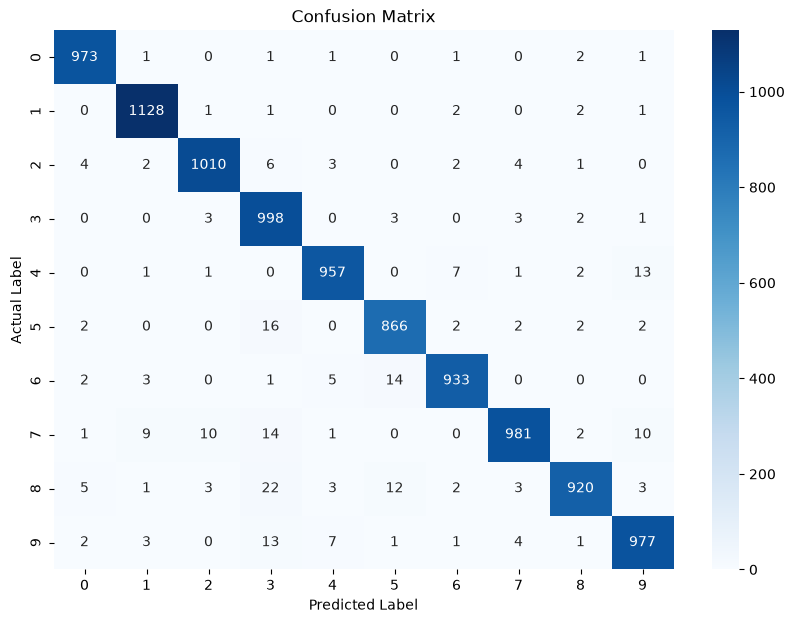

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Final Model Accuracy: {accuracy * 100:.2f}%")

Final Model Accuracy: 97.43%


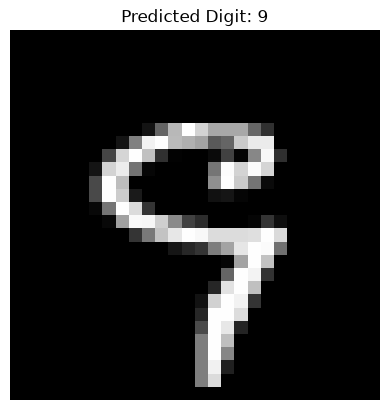

Actual Digit: 9
Predicted Digit: 9


In [17]:
index = np.random.randint(0, len(X_test))

image = X_test[index]

prediction = model.predict(
    image.reshape(1, 28, 28),
    verbose=0
)

predicted_digit = np.argmax(prediction)

plt.imshow(image, cmap='gray')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis('off')
plt.show()

print("Actual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)

In [18]:
model.save("mnist_digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [19]:
from tensorflow.keras.models import load_model

loaded_model = load_model("mnist_digit_model.keras")

print("Saved model loaded successfully!")

Saved model loaded successfully!
